In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import trange
from scipy.optimize import minimize
from scipy.linalg import orth
from tqdm import trange
import helpers_attractors as h
import importlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.interpolate import CubicSpline, RectBivariateSpline
from matplotlib.path import Path
from matplotlib.colors import Normalize
from matplotlib import cm
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage import measure
import matplotlib.patches as mpatches
device = "cuda" if torch.cuda.is_available() else "cpu"
import pandas as pd


In [24]:
df = pd.DataFrame(
    index=[
        "Spectral radius",
        "Participation ratio (mean)",
        "Participation ratio (dominant)"
    ],
    columns=["Rössler", "Dadras", "Havlorsen", "Lorenz"]
)

In [29]:
df.loc["Spectral radius", "Lorenz"] = np.loadtxt('lorenz_spec_rad.txt')
df.loc["Spectral radius", "Rössler"] = np.loadtxt('rossler_spec_rad.txt')
df.loc["Spectral radius", "Dadras"] = np.loadtxt('dadras_spec_rad.txt')
df.loc["Spectral radius", "Havlorsen"] = np.loadtxt('havlorsen_spec_rad.txt')

df.loc["Participation ratio (mean)", "Lorenz"] = np.loadtxt('lorenz_avg_pr.txt')/1024
df.loc["Participation ratio (mean)", "Rössler"] = np.loadtxt('rossler_avg_pr.txt')/1024
df.loc["Participation ratio (mean)", "Dadras"] = np.loadtxt('dadras_avg_pr.txt')/1024
df.loc["Participation ratio (mean)", "Havlorsen"] = np.loadtxt('havlorsen_avg_pr.txt')/1024

df.loc["Participation ratio (dominant)", "Lorenz"] = np.loadtxt('lorenz_dom_pr.txt')/1024
df.loc["Participation ratio (dominant)", "Rössler"] = np.loadtxt('rossler_dom_pr.txt')/1024
df.loc["Participation ratio (dominant)", "Dadras"] = np.loadtxt('dadras_dom_pr.txt')/1024
df.loc["Participation ratio (dominant)", "Havlorsen"] = np.loadtxt('havlorsen_dom_pr.txt')/1024

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_91191/602592584.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


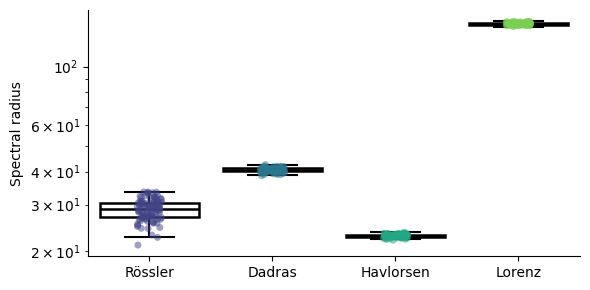

In [31]:
systems = ["Rössler", "Dadras", "Havlorsen", "Lorenz"]

rows = []
for system in systems:
    arr = df.loc["Spectral radius", system]
    for val in arr:
        rows.append({"system": system, "value": val})

data = pd.DataFrame(rows)

plt.figure(figsize=(6,3))
sns.boxplot(
    x="system", y="value", data=data,
    whis=1.5, showfliers=False,
    boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.8},
    whiskerprops={"color": "black", "linewidth": 1.5},
    capprops={"color": "black", "linewidth": 1.5},
    medianprops={"color": "black", "linewidth": 1.8},
    zorder=1
)

sns.stripplot(
    x="system", y="value", data=data,
    jitter=True, size=5, alpha=0.5,
    palette="viridis",
    zorder=2
)
plt.yscale('log')

plt.xlabel("")
plt.ylabel("Spectral radius")
sns.despine()
plt.tight_layout()
plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_91191/3174278927.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


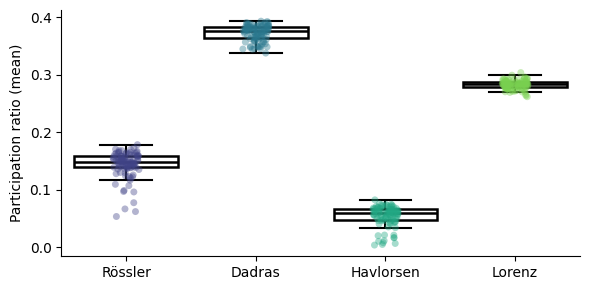

In [36]:
systems = ["Rössler", "Dadras", "Havlorsen", "Lorenz"]

rows = []
for system in systems:
    arr = df.loc["Participation ratio (mean)", system]
    for val in arr:
        rows.append({"system": system, "value": val})

data = pd.DataFrame(rows)

plt.figure(figsize=(6,3))
sns.boxplot(
    x="system", y="value", data=data,
    whis=1.5, showfliers=False,
    boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.8},
    whiskerprops={"color": "black", "linewidth": 1.5},
    capprops={"color": "black", "linewidth": 1.5},
    medianprops={"color": "black", "linewidth": 1.8},
    zorder=1
)

sns.stripplot(
    x="system", y="value", data=data,
    jitter=True, size=5, alpha=0.4,
    palette="viridis",
    zorder=2
)

plt.xlabel("")
plt.ylabel("Participation ratio (mean)")
sns.despine()
plt.tight_layout()
plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_91191/157066912.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


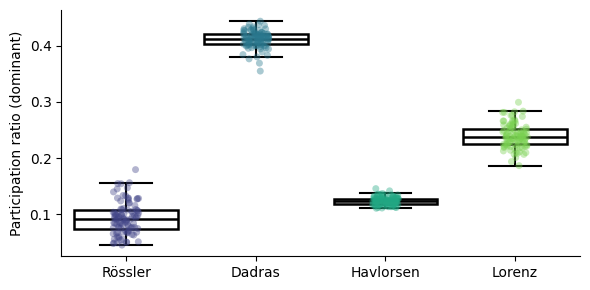

In [37]:
systems = ["Rössler", "Dadras", "Havlorsen", "Lorenz"]

rows = []
for system in systems:
    arr = df.loc["Participation ratio (dominant)", system]
    for val in arr:
        rows.append({"system": system, "value": val})

data = pd.DataFrame(rows)

plt.figure(figsize=(6,3))
sns.boxplot(
    x="system", y="value", data=data,
    whis=1.5, showfliers=False,
    boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.8},
    whiskerprops={"color": "black", "linewidth": 1.5},
    capprops={"color": "black", "linewidth": 1.5},
    medianprops={"color": "black", "linewidth": 1.8},
    zorder=1
)

sns.stripplot(
    x="system", y="value", data=data,
    jitter=True, size=5, alpha=0.4,
    palette="viridis",
    zorder=2
)

plt.xlabel("")
plt.ylabel("Participation ratio (dominant)")
sns.despine()
plt.tight_layout()
plt.show()